# Onyx Mine — DGPS Survey Map

This notebook creates a **fixed, square satellite map** of three DGPS survey files and saves a print-ready PNG and PDF. Run the code cells **from top to bottom** using **Kernel → Restart Kernel and Run All Cells**.

- **EM31 & Gravity surveys:** all points retained.
- **ERT surveys:** the **two westernmost** points removed from the plot.
- **Mine tunnel 1 opening:** only the **easternmost** Senior Design point retained.

Original CSV files are never modified. Change file paths, colors, labels, map center, map size, and export settings in **Cell 2: Settings**. The aerial imagery is retrieved online from USGS NAIP.

In [1]:
# 1. IMPORTS
from pathlib import Path
from io import BytesIO

import matplotlib.pyplot as plt
import pandas as pd
import requests
from PIL import Image, UnidentifiedImageError
from pyproj import Transformer


In [2]:
# 2. SETTINGS — EDIT HERE

# CSV files: paths are relative to Jupyter's current working directory.
DATA_DIR = Path("../../Data/DGPS data")
FILE_NAMES = [
    "onyx_101726.csv",                 # EM31 & Gravity
    "onyx_ert_92726.csv",              # ERT
    "onyx_senior_design_092625.csv",   # Mine tunnel opening
]

# The order below matches FILE_NAMES above.
colors = ["red", "cyan", "yellow"]
legend_names = [
    "EM31 & Gravity surveys",
    "ERT surveys",
    "Mine tunnel 1 opening",
]

# Stationary square map — centered on the mine-opening point.
MAP_CENTER_LAT = 40.478863
MAP_CENTER_LON = -106.835294
MAP_SIZE = 200        # Square map side length in Web Mercator projected meters

# Figure and marker appearance
FIG_WIDTH = 7         # Print width (inches)
FIG_HEIGHT = 7        # Print height (inches)
DPI = 300
POINT_SIZE = 12
IMAGE_RESOLUTION = 3200    # Requested USGS image width/height (pixels)
MAP_TITLE = "Onyx Mine DGPS Survey Locations"
OUTPUT_STEM = "onyx mine survey map senior design"  # No file extension

assert len(FILE_NAMES) == len(colors) == len(legend_names), (
    "FILE_NAMES, colors, and legend_names must have the same length."
)
assert MAP_SIZE > 0 and IMAGE_RESOLUTION > 0
print(f"Notebook working directory: {Path.cwd()}")
print(f"Looking for DGPS CSVs in: {DATA_DIR.resolve()}")


Notebook working directory: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\GPS
Looking for DGPS CSVs in: C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\Data\DGPS data


In [3]:
# 3. LOAD AND CLEAN ORIGINAL DGPS DATA

surveys = []
for file_name in FILE_NAMES:
    file_path = DATA_DIR / file_name
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Cannot find {file_path.resolve()}\n"
            "Edit DATA_DIR or FILE_NAMES in Cell 2 to match your file locations."
        )

    df = pd.read_csv(file_path)
    cols = {str(c).strip().lower(): c for c in df.columns}
    lat_col = next((cols[k] for k in ("latitude", "lat") if k in cols), None)
    lon_col = next((cols[k] for k in ("longitude", "lon", "long") if k in cols), None)
    if lat_col is None or lon_col is None:
        raise ValueError(
            f"{file_name} has no recognizable latitude/longitude columns. "
            f"Found: {list(df.columns)}"
        )

    df = df.copy()
    df["Latitude"] = pd.to_numeric(df[lat_col], errors="coerce")
    df["Longitude"] = pd.to_numeric(df[lon_col], errors="coerce")
    df = df.dropna(subset=["Latitude", "Longitude"])
    df = df.loc[
        df["Latitude"].between(-90, 90)
        & df["Longitude"].between(-180, 180)
    ].copy()
    if df.empty:
        raise ValueError(f"{file_name} contains no valid decimal-degree coordinates.")

    surveys.append((file_name, df))
    print(f"Loaded {file_name}: {len(df)} valid points")


Loaded onyx_101726.csv: 112 valid points
Loaded onyx_ert_92726.csv: 130 valid points
Loaded onyx_senior_design_092625.csv: 10 valid points


In [4]:
# 4. FILTER POINTS FOR THE MAP (ORIGINAL DATA REMAINS UNCHANGED)

ert_df = next(df for name, df in surveys if "ert_92726" in name.lower())
senior_df = next(df for name, df in surveys if "senior" in name.lower())

if len(ert_df) < 3:
    raise ValueError("ERT file needs at least 3 points to remove its two westernmost points.")

# Smaller / more-negative longitude means farther west.
removed_ert_points = ert_df.nsmallest(2, "Longitude").copy()
ert_clean_df = ert_df.drop(index=removed_ert_points.index).copy()

# Larger / less-negative longitude means farther east.
mine_opening_df = senior_df.nlargest(1, "Longitude").copy()

# Rebuild final data list without changing the three originals in 'surveys'.
plot_surveys = [
    (
        name,
        mine_opening_df if "senior" in name.lower()
        else ert_clean_df if "ert_92726" in name.lower()
        else df,
    )
    for name, df in surveys
]

print(f"ERT: {len(ert_df)} original → {len(ert_clean_df)} plotted")
print(f"Senior Design: {len(senior_df)} original → {len(mine_opening_df)} plotted")
print("Removed ERT point indices:", list(removed_ert_points.index))
print("Mine-opening point index:", list(mine_opening_df.index))


ERT: 130 original → 128 plotted
Senior Design: 10 original → 1 plotted
Removed ERT point indices: [0, 1]
Mine-opening point index: [2]


In [5]:
# 5. SET THE FIXED MAP EXTENT AND DOWNLOAD USGS AERIAL IMAGERY
# Re-run this cell after changing MAP_CENTER_LAT/LON, MAP_SIZE, or IMAGE_RESOLUTION.
# Imagery requires an internet connection. If it is temporarily unavailable,
# the following plot cell still runs, with a blank background.

transformer = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
center_x, center_y = transformer.transform(MAP_CENTER_LON, MAP_CENTER_LAT)
half_size = MAP_SIZE / 2
xmin, xmax = center_x - half_size, center_x + half_size
ymin, ymax = center_y - half_size, center_y + half_size

image_url = (
    "https://imagery.nationalmap.gov/arcgis/rest/"
    "services/USGSNAIPImagery/ImageServer/exportImage"
)
image_params = {
    "bbox": f"{xmin},{ymin},{xmax},{ymax}",
    "bboxSR": 3857,
    "imageSR": 3857,
    "size": f"{IMAGE_RESOLUTION},{IMAGE_RESOLUTION}",
    "format": "jpg",
    "f": "image",
}

satellite_image = None
try:
    response = requests.get(image_url, params=image_params, timeout=90)
    response.raise_for_status()
    satellite_image = Image.open(BytesIO(response.content)).convert("RGB")
    print(f"USGS aerial imagery loaded: {satellite_image.width} × {satellite_image.height} px")
except (requests.RequestException, UnidentifiedImageError, OSError) as exc:
    print(f"WARNING: USGS imagery could not be loaded: {exc}")
    print("The next cell will plot the DGPS points without a satellite background.")


USGS aerial imagery loaded: 3200 × 3200 px


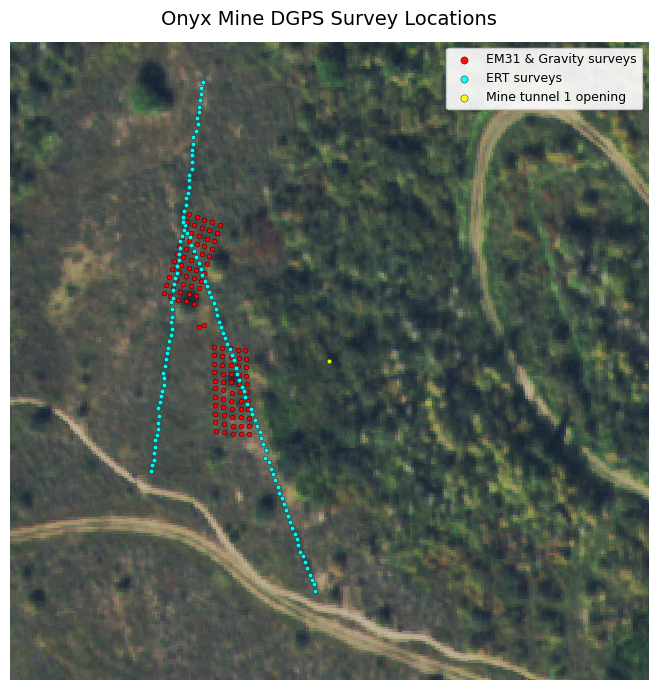

In [6]:
# 6. DRAW THE STATIC SQUARE MAP
# Re-run this cell after changing markers, labels, or colors (no new imagery download).

fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))

if satellite_image is not None:
    ax.imshow(
        satellite_image,
        extent=[xmin, xmax, ymin, ymax],
        origin="upper",
        interpolation="nearest",
        zorder=0,
    )

for (file_name, df), color, name in zip(plot_surveys, colors, legend_names):
    x, y = transformer.transform(
        df["Longitude"].to_numpy(),
        df["Latitude"].to_numpy(),
    )
    ax.scatter(
        x, y,
        s=POINT_SIZE,
        color=color,
        edgecolors="black",
        linewidths=0.3,
        alpha=0.95,
        label=name,          # Use custom legend name, NOT file_name.
        zorder=5,
    )

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.set_box_aspect(1)
ax.set_axis_off()
ax.legend(loc="upper right", fontsize=9, markerscale=1.5,
          framealpha=0.9, facecolor="white")
ax.set_title(MAP_TITLE, fontsize=14, pad=12)
fig.tight_layout()
plt.show()
